# Manufacturing Downtime – Next-Day Forecast

Runs `scripts/04_forecast.py` and answers three forecasting questions:

1. **How much downtime is expected tomorrow, and how many batches can be produced?**
   Three ways of estimating downtime per batch are compared with leave-one-out cross-validation (overall average, product average, regression on product + operator + shift), and the method with the lowest error is used:

   `Planned batches = Available minutes / (Min batch time + Expected downtime per batch)`
2. **Which downtime causes are expected to cost the most minutes tomorrow?**
3. **How many batches can the line make tomorrow if each operator runs it?**

In [1]:
%run ../scripts/04_forecast.py

Leave-one-out error (mean absolute error, minutes per batch):
                                 Method  MAE_Minutes
                        Overall average        19.06
             Product average (baseline)        20.74
Regression (product + operator + shift)        20.78

Using: Overall average

Forecast for 2024-09-04 (1440 available minutes):
ProductID  Expected_Downtime_Per_Batch  Expected_Cycle_Min  Planned_Batches  Batches_If_No_Downtime
   OR-600                         36.5                96.5               14                      24
   LE-600                         36.5                96.5               14                      24
   CO-600                         36.5                96.5               14                      24
   DC-600                         36.5                96.5               14                      24
   RB-600                         36.5                96.5               14                      24
    CO-2L                         36.5             


Batches of CO-600 if each operator runs the line:
Operator_Name  Expected_Downtime_Per_Batch  Planned_Batches
      Charlie                         34.9               15
          Dee                         33.6               15
       Dennis                         37.8               14
          Mac                         41.5               14

Wrote sql/07_forecast_table.sql


## Method comparison (lower error is better)

In [2]:
import pandas as pd
pd.read_csv("../data/forecast/model_comparison.csv")

,Method,MAE_Minutes
0,Overall average,19.06
1,Product average (baseline),20.74
2,Regression (product + operator + shift),20.78


## Q1. Next-day downtime and batch plan

In [3]:
pd.read_csv("../data/forecast/next_day_forecast.csv")

,Forecast_Date,ProductID,Flavor,Size,Min_Batch_Time,Expected_Downtime_Per_Batch,Expected_Cycle_Min,Available_Min,Planned_Batches,Batches_If_No_Downtime,Expected_Downtime_Day,Method
0,2024-09-04,OR-600,Orange,600 ml,60,36.5,96.5,1440,14,24,511,Overall average
1,2024-09-04,LE-600,Lemon Lime,600 ml,60,36.5,96.5,1440,14,24,511,Overall average
2,2024-09-04,CO-600,Cola,600 ml,60,36.5,96.5,1440,14,24,511,Overall average
3,2024-09-04,DC-600,Diet Cola,600 ml,60,36.5,96.5,1440,14,24,511,Overall average
4,2024-09-04,RB-600,Root Beer,600 ml,60,36.5,96.5,1440,14,24,511,Overall average
5,2024-09-04,CO-2L,Cola,2 L,98,36.5,134.5,1440,10,14,365,Overall average


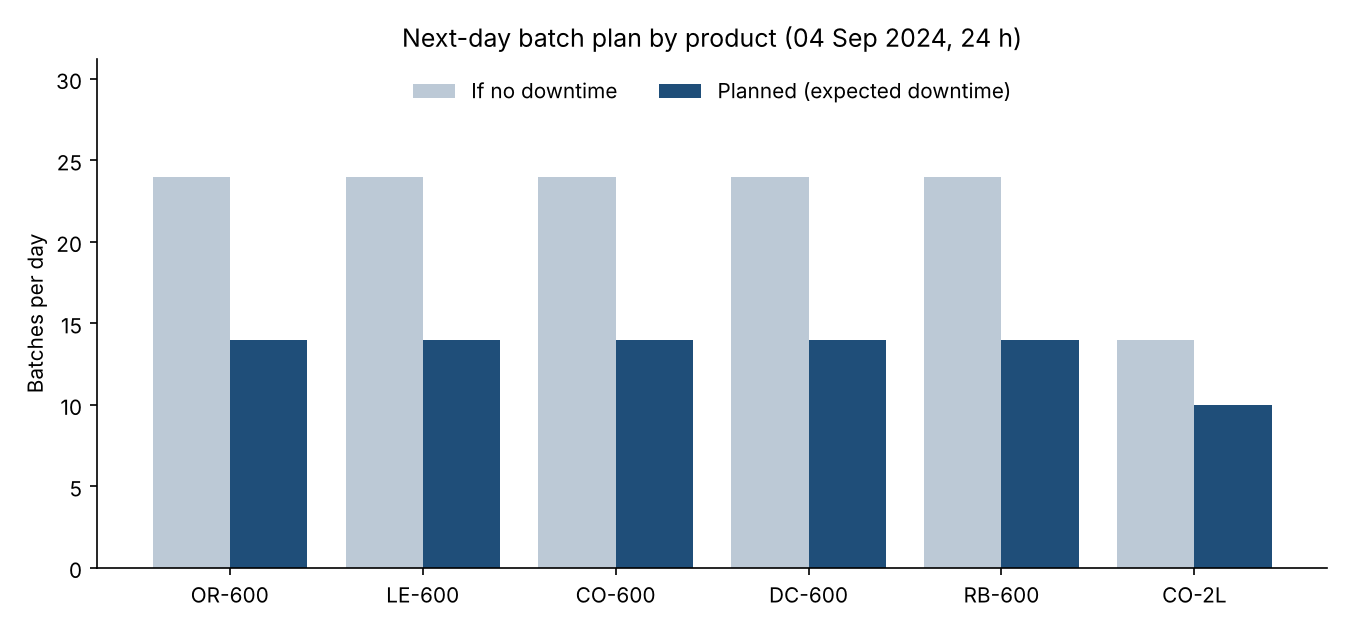

In [4]:
from IPython.display import Image
Image("../reports/figures/06_forecast_batches.png")

## Q2. Which causes will cost the most minutes tomorrow?
Each cause's share of historical downtime per batch, applied to the planned batches of the most produced product.

In [5]:
pd.read_csv("../data/forecast/next_day_downtime_by_cause.csv")

,Forecast_Date,Planned_Product,Description,Factor_Category,Expected_Min_Per_Batch,Expected_Min_Next_Day
0,2024-09-04,CO-600,Machine adjustment,Human,8.74,122
1,2024-09-04,CO-600,Machine failure,Machine,6.68,94
2,2024-09-04,CO-600,Inventory shortage,Material,5.92,83
3,2024-09-04,CO-600,Batch change,Human,4.21,59
4,2024-09-04,CO-600,Batch coding error,Human,3.82,53
5,2024-09-04,CO-600,Other,Other,1.95,27
6,2024-09-04,CO-600,Product spill,Human,1.50,21
7,2024-09-04,CO-600,Calibration error,Human,1.29,18
8,2024-09-04,CO-600,Labeling error,Machine,1.11,16
9,2024-09-04,CO-600,Label switch,Human,0.87,12


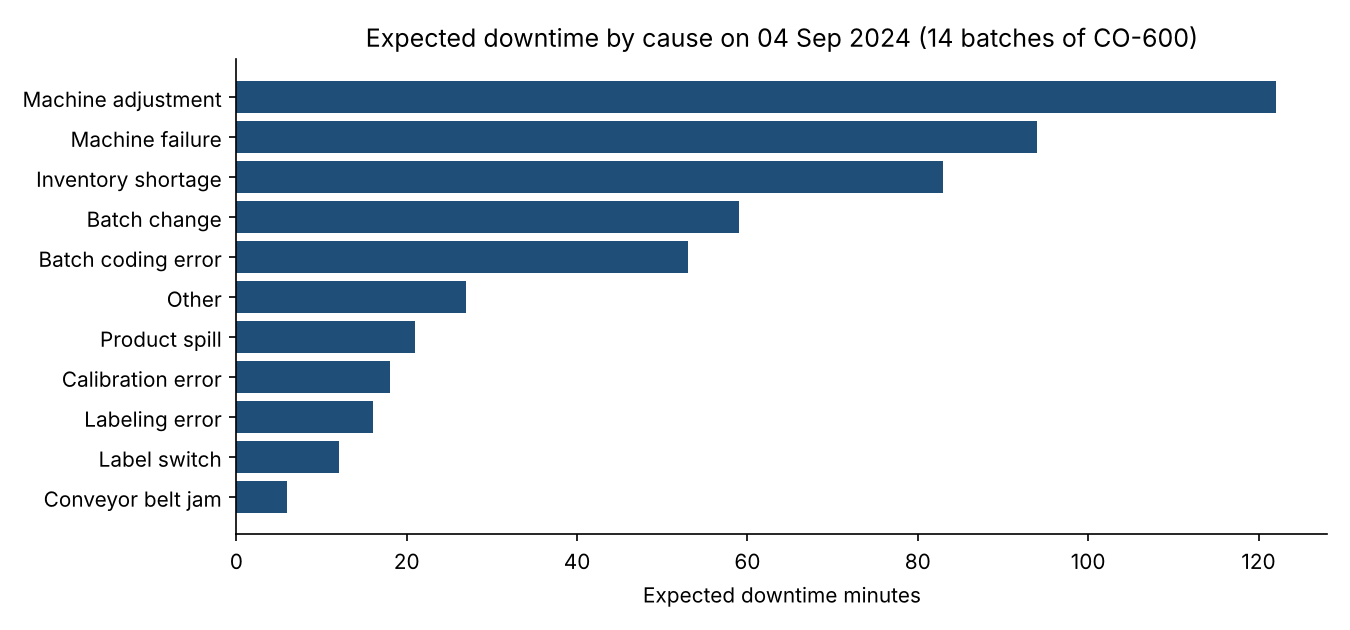

In [6]:
Image("../reports/figures/07_forecast_by_cause.png")

## Q3. How many batches if each operator runs the line?
Each operator's average downtime per batch gives a different batch time, and so a different number of batches.

In [7]:
pd.read_csv("../data/forecast/next_day_batches_by_operator.csv")

,Forecast_Date,Planned_Product,Operator_Name,Shift,Expected_Downtime_Per_Batch,Expected_Cycle_Min,Planned_Batches
0,2024-09-04,CO-600,Charlie,Evening,34.9,94.9,15
1,2024-09-04,CO-600,Dee,Morning,33.6,93.6,15
2,2024-09-04,CO-600,Dennis,Morning,37.8,97.8,14
3,2024-09-04,CO-600,Mac,Evening,41.5,101.5,14


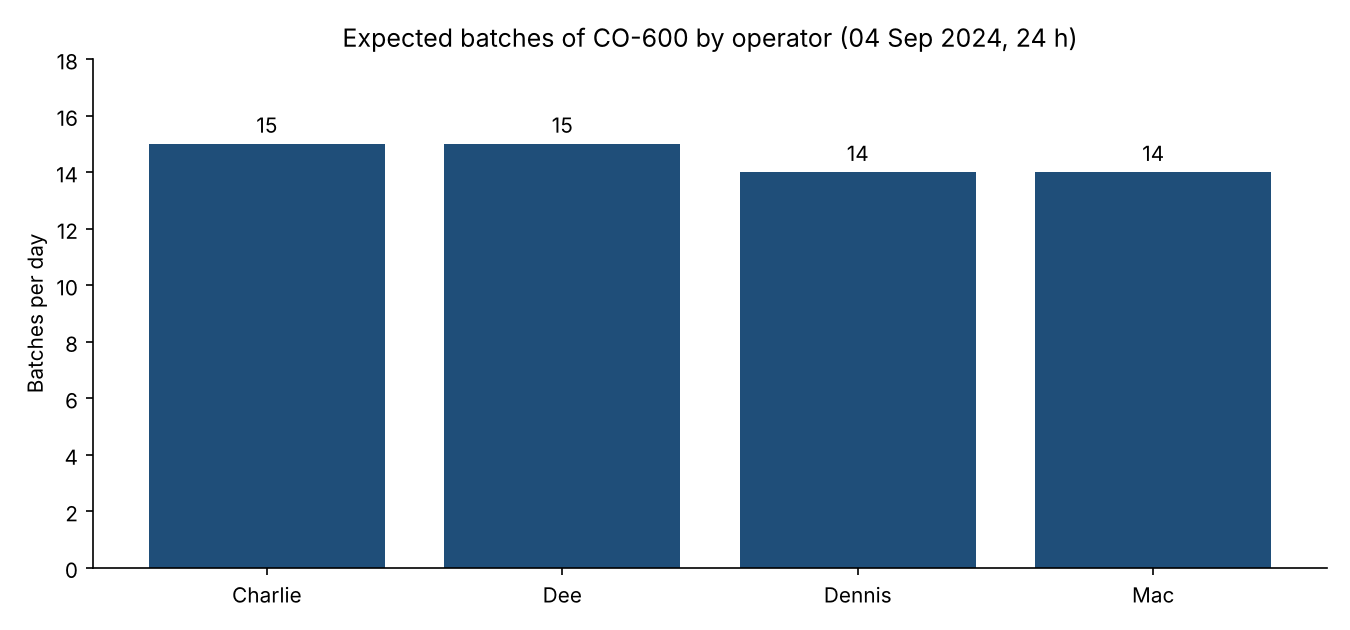

In [8]:
Image("../reports/figures/08_forecast_by_operator.png")

## Notes
- With only 38 batches over 5 days, knowing the product, operator or shift does not predict a batch's downtime better than the overall average, so the overall average is used.
- A stronger model needs more history. If required, more data can be generated following the same patterns as the real data and the comparison above re-run.
- `AVAILABLE_MINUTES` in the script is set to 24 hours; change it if the line runs fewer hours.